# Momento 3 · Tiendas de barrio: inferencia y modelo

Tercera etapa del mismo proyecto: el pitch del Momento 2 afirmó que las tiendas de barrio (OUT019 y OUT010)
dejan unos 2,1 millones al año sin vender frente a un Supermercado Tipo 1, y propuso un piloto de tres meses
con OUT019. Este notebook pone **incertidumbre** a esa afirmación (secciones 1 a 8) y la contrasta con un
**modelo de machine learning** (sección 9 en adelante).

**Regla de trazabilidad.** Cada cifra se calcula en una celda de código y su procedimiento está en el
markdown de al lado y en `cifras_y_procedimientos.md`. Las frases de interpretación se imprimen desde el
código con las cifras calculadas, no se transcriben a mano.

**Unidad de análisis.** Cada fila del dataset es un producto en una tienda, con su venta del año. "Venta por
producto" es el valor de `Item_Outlet_Sales` de esa fila. Las unidades monetarias son las del dataset.

## 0. Entorno, datos y limpieza

Se carga `../dataset/train.csv` (solo lectura). La limpieza es la del Momento 1: la visibilidad igual a 0
(526 filas) se trata como dato no registrado y se rellena con la mediana del mismo producto en las otras
tiendas (respaldo: mediana del tipo de producto). **Aquí es descriptiva**, calculada sobre todo el dataset,
como en el M1. Para el modelo (sección 9 en adelante) la imputación se rehace dentro del `Pipeline`,
ajustada solo con entrenamiento, para no filtrar información del conjunto de prueba.

"Vitrina" es el porcentaje del área de exhibición que ocupa un producto (`Item_Visibility` x 100).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

RANDOM_STATE = 42
RUTA = "../dataset/train.csv"
if not Path(RUTA).exists():
    raise FileNotFoundError(f"No se encuentra {RUTA}. El notebook debe estar en la carpeta Momento3.")
print("Intérprete:", sys.executable)


def fmt(x, d=0):
    """Número con formato español: punto de miles y coma decimal."""
    return f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def fmt_p(p):
    return "menor que 0,001" if p < 0.001 else fmt(p, 3)


df = pd.read_csv(RUTA)
V = "Item_Outlet_Sales"

vis0 = df["Item_Visibility"].replace(0, np.nan)
vis = vis0.fillna(vis0.groupby(df["Item_Identifier"]).transform("median"))
df["vitrina"] = vis.fillna(vis0.groupby(df["Item_Type"]).transform("median")) * 100

df["formato"] = np.select(
    [df["Outlet_Type"] == "Grocery Store", df["Outlet_Type"] == "Supermarket Type1"],
    ["Tienda de barrio", "Supermercado Tipo 1"],
    default="Otro supermercado",
)
barrio = df.loc[df["formato"] == "Tienda de barrio", V]
tipo1 = df.loc[df["formato"] == "Supermercado Tipo 1", V]
print(f"Filas: {len(df)} | tienda de barrio: {len(barrio)} | Supermercado Tipo 1: {len(tipo1)}")

Intérprete: /home/breiner/Development/data_analysis/analitica-datos-estudiantes/.venv/bin/python
Filas: 8523 | tienda de barrio: 1083 | Supermercado Tipo 1: 5577


## 1. Descriptivos antes de cualquier prueba

Se comparan los dos formatos que el pitch pone frente a frente: **tienda de barrio** (`Grocery Store`, OUT019 y
OUT010) y **Supermercado Tipo 1**. Se dejan fuera los supermercados Tipo 2 y 3 porque el techo del M2 se
calculó contra Tipo 1. Se reportan `n`, media, desviación estándar, mediana y sesgo: las ventas tienen cola a la
derecha, por eso la mediana también.

In [2]:
def descriptivos(x):
    return pd.Series({
        "n": len(x), "media": x.mean(), "desviación estándar": x.std(ddof=1),
        "mediana": x.median(), "mínimo": x.min(), "máximo": x.max(), "sesgo": x.skew(),
    })


desc = pd.DataFrame({"Tienda de barrio": descriptivos(barrio), "Supermercado Tipo 1": descriptivos(tipo1)}).T
display(desc.round(2))

,n,media,desviación estándar,mediana,mínimo,máximo,sesgo
Tienda de barrio,1083.0,339.83,260.85,257.00,33.29,1775.69,1.59
Supermercado Tipo 1,5577.0,2316.18,1515.97,1990.74,73.24,10256.65,1.05


## 2. Dos intervalos de confianza al 95 %

**Procedimiento.** Para cada formato: intervalo de confianza de la media con la distribución t,
`stats.t.interval(0.95, df=n-1, loc=media, scale=error_estandar)`, donde el error estándar es
`desviación estándar / raíz(n)` (no la desviación estándar). Fórmula: media ± t(0,975; n-1) x error estándar.
Se aplica `dropna()` antes, y se reporta `n`.

**Lectura correcta.** Un intervalo al 95 % no dice que la media verdadera tenga 95 % de probabilidad de estar
dentro. Dice que, si se repitiera el muestreo muchas veces, 95 % de los intervalos construidos así contendrían
la media verdadera.

In [3]:
def ic95(x):
    x = x.dropna()
    n, media, ee = len(x), x.mean(), stats.sem(x)
    inferior, superior = stats.t.interval(0.95, df=n - 1, loc=media, scale=ee)
    return {"n": n, "media": media, "error estándar": ee, "IC95 inferior": inferior, "IC95 superior": superior}


ic = pd.DataFrame({"Tienda de barrio": ic95(barrio), "Supermercado Tipo 1": ic95(tipo1)}).T
display(ic.round(2))

for nombre, fila in ic.iterrows():
    print(f"{nombre}: con n = {fmt(fila['n'])} productos, la venta media por producto está entre "
          f"{fmt(fila['IC95 inferior'])} y {fmt(fila['IC95 superior'])} (media muestral {fmt(fila['media'])}), al 95 % de confianza.")
print("\nLos dos intervalos no se solapan:", ic.loc['Tienda de barrio', 'IC95 superior'] < ic.loc['Supermercado Tipo 1', 'IC95 inferior'])

,n,media,error estándar,IC95 inferior,IC95 superior
Tienda de barrio,1083.0,339.83,7.93,324.28,355.38
Supermercado Tipo 1,5577.0,2316.18,20.30,2276.39,2355.98


Tienda de barrio: con n = 1.083 productos, la venta media por producto está entre 324 y 355 (media muestral 340), al 95 % de confianza.
Supermercado Tipo 1: con n = 5.577 productos, la venta media por producto está entre 2.276 y 2.356 (media muestral 2.316), al 95 % de confianza.

Los dos intervalos no se solapan: True


## 3. Prueba de hipótesis: ¿difiere la venta por producto entre formatos?

Los cuatro pasos, con H0 y H1 fijadas **antes** de la celda que calcula la prueba:

1. **Hipótesis.**
   - H0: la venta media por producto en tiendas de barrio es igual a la de un Supermercado Tipo 1.
   - H1: las dos ventas medias son distintas (prueba de dos colas).
2. **Nivel de significancia:** alfa = 0,05.
3. **Estadístico:** t de Welch, `stats.ttest_ind(tipo1, barrio, equal_var=False)`. Es el estadístico de la
   diferencia de medias medido en errores estándar:
   `t = (media_1 - media_2) / raíz(s1²/n1 + s2²/n2)`. Se usa Welch porque no supone igual varianza en los dos
   grupos; abajo se verifica ese supuesto en vez de darlo por hecho.
4. **Decisión:** se rechaza H0 si el p-valor es menor que alfa.

**Aviso de honestidad.** El equipo ya conocía las dos medias por el Momento 2, así que no hay suspenso sobre el
resultado. El valor de esta sección no es el p-valor sino el **tamaño de la diferencia y su incertidumbre**:
con más de mil filas por grupo casi cualquier diferencia sale significativa.

**Supuestos que se verifican:** (a) varianzas distintas: prueba de Levene; (b) forma: con n grande el
teorema central del límite sostiene la prueba de medias aunque las ventas tengan sesgo, y se confirma con
Mann-Whitney, que no supone normalidad; (c) independencia: es la que más se estira, ver la sección 5.

In [4]:
levene = stats.levene(tipo1, barrio)
print(f"Levene (igualdad de varianzas): estadístico = {fmt(levene.statistic, 1)}, p = {fmt_p(levene.pvalue)}; "
      f"desviación estándar Tipo 1 = {fmt(tipo1.std())}, tienda de barrio = {fmt(barrio.std())}")

welch = stats.ttest_ind(tipo1, barrio, equal_var=False)
ci_dif = welch.confidence_interval(confidence_level=0.95)

# Comprobación a mano con la fórmula de Welch
n1, n2 = len(tipo1), len(barrio)
v1, v2 = tipo1.var(ddof=1) / n1, barrio.var(ddof=1) / n2
dif = tipo1.mean() - barrio.mean()
ee_dif = np.sqrt(v1 + v2)
gl = (v1 + v2) ** 2 / (v1**2 / (n1 - 1) + v2**2 / (n2 - 1))
t_mano = dif / ee_dif
ic_mano = stats.t.interval(0.95, df=gl, loc=dif, scale=ee_dif)
assert np.isclose(t_mano, welch.statistic) and np.isclose(gl, welch.df) and np.isclose(ic_mano[0], ci_dif.low)

sp = np.sqrt(((n1 - 1) * tipo1.var(ddof=1) + (n2 - 1) * barrio.var(ddof=1)) / (n1 + n2 - 2))
d_cohen = dif / sp
razon = tipo1.mean() / barrio.mean()
mw = stats.mannwhitneyu(tipo1, barrio, alternative="two-sided")

print(f"\nDiferencia de medias (Tipo 1 menos tienda de barrio): {fmt(dif)}")
print(f"Welch: t = {fmt(welch.statistic, 1)}, grados de libertad = {fmt(gl, 0)}, p = {fmt_p(welch.pvalue)}")
print(f"IC 95 % de la diferencia: [{fmt(ci_dif.low)}, {fmt(ci_dif.high)}]  (comprobado a mano con la fórmula de Welch)")
print(f"d de Cohen = {fmt(d_cohen, 2)} (desviación combinada {fmt(sp)}); razón de medias = {fmt(razon, 1)} veces")
print(f"Mann-Whitney (robustez, sin supuesto de normalidad): p = {fmt_p(mw.pvalue)}")

print(f"\nDecisión con alfa = 0,05: {'se rechaza H0' if welch.pvalue < 0.05 else 'no se rechaza H0'}.")
print(f"Relevancia práctica: en promedio un Supermercado Tipo 1 vende {fmt(razon, 1)} veces lo que vende una tienda "
      f"de barrio por producto; la diferencia está entre {fmt(ci_dif.low)} y {fmt(ci_dif.high)} por producto al 95 % de confianza. "
      f"El intervalo no contiene el cero y el efecto no es marginal (d = {fmt(d_cohen, 2)}).")

Levene (igualdad de varianzas): estadístico = 1.026,4, p = menor que 0,001; desviación estándar Tipo 1 = 1.516, tienda de barrio = 261

Diferencia de medias (Tipo 1 menos tienda de barrio): 1.976
Welch: t = 90,7, grados de libertad = 6.614, p = menor que 0,001
IC 95 % de la diferencia: [1.934, 2.019]  (comprobado a mano con la fórmula de Welch)
d de Cohen = 1,42 (desviación combinada 1.391); razón de medias = 6,8 veces
Mann-Whitney (robustez, sin supuesto de normalidad): p = menor que 0,001

Decisión con alfa = 0,05: se rechaza H0.
Relevancia práctica: en promedio un Supermercado Tipo 1 vende 6,8 veces lo que vende una tienda de barrio por producto; la diferencia está entre 1.934 y 2.019 por producto al 95 % de confianza. El intervalo no contiene el cero y el efecto no es marginal (d = 1,42).


## 4. Robustez: comparar el mismo producto en los dos formatos

La prueba anterior compara filas distintas y podría confundir "el formato" con "qué productos se venden en cada
formato". Se repite comparando **el mismo producto**: para cada producto que se vende en ambos formatos, la
venta media en Tipo 1 menos la venta media en tienda de barrio. Se aplica un t de una muestra sobre esas
diferencias (equivale a la prueba t pareada) y un intervalo de confianza de la diferencia media.

In [5]:
m_barrio = df[df["formato"] == "Tienda de barrio"].groupby("Item_Identifier")[V].mean()
m_tipo1 = df[df["formato"] == "Supermercado Tipo 1"].groupby("Item_Identifier")[V].mean()
comunes = m_barrio.index.intersection(m_tipo1.index)
dif_prod = (m_tipo1[comunes] - m_barrio[comunes]).dropna()

pareada = stats.ttest_rel(m_tipo1[comunes], m_barrio[comunes])
ic_par = stats.t.interval(0.95, df=len(dif_prod) - 1, loc=dif_prod.mean(), scale=stats.sem(dif_prod))
razon_mediana = (m_tipo1[comunes] / m_barrio[comunes]).median()

print(f"Productos presentes en ambos formatos: n = {len(dif_prod)}")
print(f"Diferencia media por producto: {fmt(dif_prod.mean())}; IC 95 %: [{fmt(ic_par[0])}, {fmt(ic_par[1])}]")
print(f"t pareado = {fmt(pareada.statistic, 1)}, p = {fmt_p(pareada.pvalue)}")
print(f"Mediana de la razón (venta Tipo 1 / venta tienda de barrio) por producto: {fmt(razon_mediana, 2)} veces")
print(f"Productos que venden más en Tipo 1: {fmt((dif_prod > 0).mean() * 100, 1)} %")
print("\nLa conclusión no cambia al comparar el mismo producto: la diferencia no se explica solo por qué productos se venden en cada formato.")

Productos presentes en ambos formatos: n = 898
Diferencia media por producto: 1.982; IC 95 %: [1.908, 2.057]
t pareado = 52,3, p = menor que 0,001
Mediana de la razón (venta Tipo 1 / venta tienda de barrio) por producto: 7,50 veces
Productos que venden más en Tipo 1: 100,0 %

La conclusión no cambia al comparar el mismo producto: la diferencia no se explica solo por qué productos se venden en cada formato.


## 4b. Comparar entre pares: no mezclar peras con manzanas

Retroalimentación del profesor (verbal): no se debe comparar supermercados con tiendas de menor nivel como si fueran
lo mismo. Se revisa dónde el pitch del M2 mezclaba cosas distintas, y se rehace emparejando por tipo de tienda y por
nivel de ciudad. Hay tres tipos de supermercado con ventas muy distintas (Tipo 1, 2 y 3), y la comparación justa de
una tienda de barrio es contra **un solo tipo**, no contra el promedio de todos.

El dataset **no tiene un par exacto** de una tienda de barrio: todas las demás tiendas son supermercados. Por eso la
comparación contra Tipo 1 sigue siendo entre formatos distintos a propósito (la pregunta es qué pasa si cambia
el formato), y se declara así. Lo que sí se puede hacer es no agregar más desigualdad encima.

In [6]:
def comparar(origen, destino, etiqueta):
    a = df[df["Outlet_Identifier"].isin(origen)].groupby("Item_Identifier")[V].mean()
    b = df[df["Outlet_Identifier"].isin(destino)].groupby("Item_Identifier")[V].mean()
    comunes = a.index.intersection(b.index)
    d = (b[comunes] - a[comunes])
    inf, sup = stats.t.interval(0.95, df=len(comunes) - 1, loc=d.mean(), scale=stats.sem(d))
    return {"comparación": etiqueta, "productos comunes": len(comunes),
            "mediana de la razón": (b[comunes] / a[comunes]).median(),
            "diferencia media": d.mean(), "IC95 inferior": inf, "IC95 superior": sup}


filas = [
    comparar(["OUT010"], ["OUT013", "OUT018", "OUT027"], "Pitch M2, nivel 3: OUT010 contra Tipo 1 + Tipo 2 + Tipo 3 (mezcla)"),
    comparar(["OUT010"], ["OUT013"], "Emparejado, nivel 3: OUT010 contra OUT013 (solo Tipo 1)"),
    comparar(["OUT019"], ["OUT046", "OUT049"], "Emparejado, nivel 1: OUT019 contra OUT046 y OUT049 (solo Tipo 1)"),
    comparar(["OUT019"], ["OUT046"], "Emparejado, nivel 1 y tamaño pequeño: OUT019 contra OUT046"),
    comparar(["OUT019"], ["OUT010"], "Entre iguales: OUT010 contra OUT019 (las dos tiendas de barrio)"),
]
pares = pd.DataFrame(filas).set_index("comparación")
display(pares.round(2))

mezcla, emp = pares.iloc[0], pares.iloc[1]
print(f"Mezclar tipos infla la razón: nivel 3 da {fmt(mezcla['mediana de la razón'], 1)} veces con Tipo 1 + 2 + 3 y {fmt(emp['mediana de la razón'], 1)} veces solo contra Tipo 1 (OUT013).")
iguales = pares.iloc[4]
print(f"Entre las dos tiendas de barrio (n = {fmt(iguales['productos comunes'])} productos comunes) la diferencia media es {fmt(iguales['diferencia media'])}, "
      f"IC 95 % [{fmt(iguales['IC95 inferior'])}, {fmt(iguales['IC95 superior'])}]: el intervalo contiene el cero, así que son comparables y se pueden agrupar.")

por_tipo = df.groupby("Outlet_Type")[V].mean()
print("\nVenta media por producto según tipo de tienda:", {k: fmt(v) for k, v in por_tipo.items()})
sup_todos = df.loc[df["Outlet_Type"] != "Grocery Store", V].mean()
print(f"El pitch comparaba 340 con {fmt(sup_todos)} (promedio de los tres tipos de supermercado, razón {fmt(sup_todos / barrio.mean(), 1)}). "
      f"Contra Tipo 1 ({fmt(tipo1.mean())}) la razón es {fmt(tipo1.mean() / barrio.mean(), 1)}. Desde el M3 la base es siempre Tipo 1 y se dice.")

,productos comunes,mediana de la razón,diferencia media,IC95 inferior,IC95 superior
comparación,,,,,
"Pitch M2, nivel 3: OUT010 contra Tipo 1 + Tipo 2 + Tipo 3 (mezcla)",522,8.50,2337.37,2205.78,2468.95
"Emparejado, nivel 3: OUT010 contra OUT013 (solo Tipo 1)",335,7.00,1934.94,1781.82,2088.06
"Emparejado, nivel 1: OUT019 contra OUT046 y OUT049 (solo Tipo 1)",445,7.25,1922.81,1803.19,2042.43
"Emparejado, nivel 1 y tamaño pequeño: OUT019 contra OUT046",308,7.00,1954.99,1796.22,2113.77
Entre iguales: OUT010 contra OUT019 (las dos tiendas de barrio),182,1.00,-25.23,-67.36,16.90


Mezclar tipos infla la razón: nivel 3 da 8,5 veces con Tipo 1 + 2 + 3 y 7,0 veces solo contra Tipo 1 (OUT013).
Entre las dos tiendas de barrio (n = 182 productos comunes) la diferencia media es -25, IC 95 % [-67, 17]: el intervalo contiene el cero, así que son comparables y se pueden agrupar.

Venta media por producto según tipo de tienda: {'Grocery Store': '340', 'Supermarket Type1': '2.316', 'Supermarket Type2': '1.995', 'Supermarket Type3': '3.694'}
El pitch comparaba 340 con 2.449 (promedio de los tres tipos de supermercado, razón 7,2). Contra Tipo 1 (2.316) la razón es 6,8. Desde el M3 la base es siempre Tipo 1 y se dice.


## 5. De la diferencia al techo en dinero, con rango

El techo del M2 es `diferencia de medias x número de filas de tienda de barrio`. Como la diferencia tiene un
intervalo de confianza, el techo también tiene un rango: se multiplican los extremos del intervalo por
las 1.083 filas. **Es un escenario, no una predicción.** Supone que las tiendas de barrio llegarían a vender como
un Tipo 1, que la brecha se repite igual cada año, y que las filas son independientes entre sí (no lo son del
todo: un mismo producto y una misma tienda aparecen varias veces, así que el intervalo real es más ancho
que el calculado aquí). Se reporta también la comparación con las ventas de toda la cadena.

In [7]:
total = df[V].sum()
techo = dif * n2
techo_inf, techo_sup = ci_dif.low * n2, ci_dif.high * n2
print(f"Techo anual puntual (escenario): {fmt(techo)}  = {fmt(techo / total * 100, 1)} % de las ventas de la cadena ({fmt(total)})")
print("Este rango recoge solo el error de muestreo de las medias; es angosto porque trata las filas como independientes, y el rango real es más ancho.")
print(f"Rango al 95 % por la incertidumbre de la media: [{fmt(techo_inf)}, {fmt(techo_sup)}]  "
      f"= [{fmt(techo_inf / total * 100, 1)} %, {fmt(techo_sup / total * 100, 1)} %] de la cadena")

Techo anual puntual (escenario): 2.140.390  = 11,5 % de las ventas de la cadena (18.591.125)
Este rango recoge solo el error de muestreo de las medias; es angosto porque trata las filas como independientes, y el rango real es más ancho.
Rango al 95 % por la incertidumbre de la media: [2.094.124, 2.186.656]  = [11,3 %, 11,8 %] de la cadena


## 6. Segunda prueba: ¿la vitrina se relaciona con las ventas?

El hallazgo 4 del pitch dice que dar más vitrina no arregla la brecha. Se contrasta con una prueba de
correlación dentro de cada formato (dentro del formato y no mezclado, porque al mezclarlos aparece una
correlación engañosa por el formato: es la paradoja de Simpson que ya mostró el Momento 1).

1. **Hipótesis.** H0: no hay correlación lineal entre vitrina y venta por producto (r = 0). H1: r es distinto de 0.
2. **Alfa:** 0,05.
3. **Estadístico:** `stats.pearsonr`, con intervalo de confianza de r por transformación de Fisher
   (`z = arctanh(r)`, error estándar `1/raíz(n-3)`).
4. **Decisión y cuidado:** si no se rechaza H0, **no se acepta** que r sea cero: se dice que no hay evidencia
   suficiente de relación y se mira el intervalo de r para saber qué tan grande podría ser como máximo.

In [8]:
filas = []
for nombre, datos in [("Tienda de barrio", df[df["formato"] == "Tienda de barrio"]),
                      ("Supermercado Tipo 1", df[df["formato"] == "Supermercado Tipo 1"])]:
    r, p = stats.pearsonr(datos["vitrina"], datos[V])
    n = len(datos)
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3)
    inf, sup = np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se)
    filas.append({"formato": nombre, "n": n, "r": r, "p-valor": p, "IC95 r inferior": inf, "IC95 r superior": sup, "r al cuadrado": r**2})
corr = pd.DataFrame(filas).set_index("formato")
display(corr.round(4))

for nombre, f in corr.iterrows():
    veredicto = "no se rechaza H0" if f["p-valor"] >= 0.05 else "se rechaza H0"
    print(f"{nombre}: r = {fmt(f['r'], 3)}, IC 95 % [{fmt(f['IC95 r inferior'], 3)}, {fmt(f['IC95 r superior'], 3)}], "
          f"p = {fmt_p(f['p-valor'])}: {veredicto}. La vitrina explicaría como mucho {fmt(max(f['IC95 r inferior']**2, f['IC95 r superior']**2) * 100, 2)} % de la variación de las ventas dentro del formato.")
print("\nNo hay evidencia de que la vitrina mueva las ventas dentro de cada formato. Eso no demuestra que no tenga ningún efecto:"
      " es ausencia de evidencia con estos datos, no prueba de ausencia.")

,n,r,p-valor,IC95 r inferior,IC95 r superior,r al cuadrado
formato,,,,,,
Tienda de barrio,1083,0.0183,0.5467,-0.0413,0.0778,0.0003
Supermercado Tipo 1,5577,-0.0111,0.4081,-0.0373,0.0152,0.0001


Tienda de barrio: r = 0,018, IC 95 % [-0,041, 0,078], p = 0,547: no se rechaza H0. La vitrina explicaría como mucho 0,61 % de la variación de las ventas dentro del formato.
Supermercado Tipo 1: r = -0,011, IC 95 % [-0,037, 0,015], p = 0,408: no se rechaza H0. La vitrina explicaría como mucho 0,14 % de la variación de las ventas dentro del formato.

No hay evidencia de que la vitrina mueva las ventas dentro de cada formato. Eso no demuestra que no tenga ningún efecto: es ausencia de evidencia con estos datos, no prueba de ausencia.


## 6b. Simulación: ¿y si se les da más vitrina?

El hallazgo 4 del pitch del M2 simuló dar más vitrina a las tiendas de barrio, pero su código no está en el
repositorio. Aquí se rehace de forma reproducible y **sin mezclar formatos**: solo tiendas de barrio y Supermercados Tipo 1.

**Procedimiento.** Regresión lineal de ventas sobre vitrina y precio de lista, con un efecto fijo por tienda
(una columna por tienda):
`ventas = b0 + b1 x vitrina + b2 x precio + efecto de la tienda + error`. El coeficiente b1 es el cambio en ventas
por cada punto porcentual más de vitrina, comparando productos de la misma tienda y del mismo precio. Su error
estándar clásico da un intervalo del 95 % (b1 ± 1,96 error estándar). Las ventas extra por dar `p` % más de vitrina
son `b1 x (vitrina actual x p / 100)` sumado sobre las 1.083 filas de tienda de barrio. Es un escenario: supone que
la relación dentro de la tienda sigue valiendo si se cambia la vitrina, lo que datos observacionales no prueban.

In [9]:
sim = df[df["formato"].isin(["Tienda de barrio", "Supermercado Tipo 1"])]
Xs = pd.concat([sim[["vitrina", "Item_MRP"]], pd.get_dummies(sim["Outlet_Identifier"], drop_first=True, dtype=float)], axis=1)
Xs.insert(0, "const", 1.0)
A, ys = Xs.values, sim[V].values
coef_s, *_ = np.linalg.lstsq(A, ys, rcond=None)
resid_s = ys - A @ coef_s
sigma2 = resid_s @ resid_s / (len(ys) - A.shape[1])
cov_s = sigma2 * np.linalg.inv(A.T @ A)
k = list(Xs.columns).index("vitrina")
b1, se_b1 = coef_s[k], np.sqrt(cov_s[k, k])
vit_barrio = df.loc[df["formato"] == "Tienda de barrio", "vitrina"]

efectos = {}
for p in (25, 50, 100):
    extra = vit_barrio.sum() * p / 100
    efectos[p] = {"efecto": b1 * extra, "inf": (b1 - 1.96 * se_b1) * extra, "sup": (b1 + 1.96 * se_b1) * extra}
print(f"Coeficiente de la vitrina: {fmt(b1, 2)} de venta por punto porcentual (IC 95 %: {fmt(b1 - 1.96 * se_b1, 2)} a {fmt(b1 + 1.96 * se_b1, 2)}); n = {fmt(len(sim))} filas")
for p, e in efectos.items():
    print(f"+{p} % de vitrina en las tiendas de barrio: ventas extra al año = {fmt(e['efecto'])} (IC 95 %: {fmt(e['inf'])} a {fmt(e['sup'])}), "
          f"es decir {fmt(e['efecto'] / total * 100, 2)} % de las ventas de la cadena")
cruza_cero = (b1 - 1.96 * se_b1) < 0 < (b1 + 1.96 * se_b1)
print(f"\nEl intervalo {'contiene' if cruza_cero else 'NO contiene'} el cero: "
      f"{'no hay evidencia de que más vitrina mueva las ventas' if cruza_cero else 'hay una relación estimada distinta de cero'}. "
      "Aun en el extremo superior del intervalo, el efecto es pequeño frente a la brecha de 2,1 millones.")

Coeficiente de la vitrina: -3,17 de venta por punto porcentual (IC 95 %: -8,36 a 2,02); n = 6.660 filas
+25 % de vitrina en las tiendas de barrio: ventas extra al año = -9.262 (IC 95 %: -24.429 a 5.906), es decir -0,05 % de las ventas de la cadena
+50 % de vitrina en las tiendas de barrio: ventas extra al año = -18.523 (IC 95 %: -48.858 a 11.811), es decir -0,10 % de las ventas de la cadena
+100 % de vitrina en las tiendas de barrio: ventas extra al año = -37.047 (IC 95 %: -97.716 a 23.623), es decir -0,20 % de las ventas de la cadena

El intervalo contiene el cero: no hay evidencia de que más vitrina mueva las ventas. Aun en el extremo superior del intervalo, el efecto es pequeño frente a la brecha de 2,1 millones.


## 7. Gráficos de la inferencia

Barras de error con los dos intervalos de confianza (`yerr` es la **mitad** del ancho del intervalo) y
boxplot comparativo con el resultado de la prueba anotado sobre el gráfico.

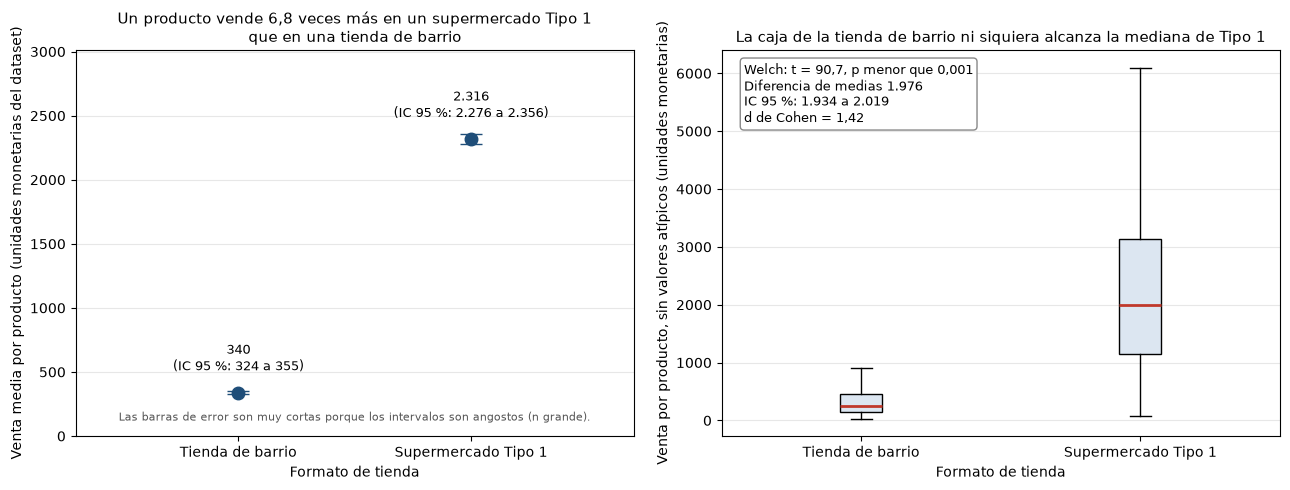

Cómo se calculó: n = 1.083 (tienda de barrio) y 5.577 (Tipo 1); intervalo t al 95 % de la media; Welch de dos colas. Boxplot sin valores atípicos solo para legibilidad: las pruebas usan todos los datos.


In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))

# Barras de error: IC 95 % de la media
nombres = list(ic.index)
medias = ic["media"].values
mitad = ((ic["IC95 superior"] - ic["IC95 inferior"]) / 2).values
posiciones = [0, 1]
ejes[0].errorbar(posiciones, medias, yerr=mitad, fmt="o", capsize=8, markersize=9, color="#1f4e79", ecolor="#1f4e79", elinewidth=2)
for x, m, h in zip(posiciones, medias, mitad):
    ejes[0].annotate(f"{fmt(m)}\n(IC 95 %: {fmt(m - h)} a {fmt(m + h)})", (x, m), textcoords="offset points", xytext=(0, 16), ha="center", fontsize=9)
ejes[0].set_xticks(posiciones, nombres)
ejes[0].set_xlim(-0.7, 1.7)
ejes[0].set_ylim(0, medias.max() * 1.3)
ejes[0].text(0.5, 0.04, "Las barras de error son muy cortas porque los intervalos son angostos (n grande).",
             transform=ejes[0].transAxes, ha="center", fontsize=8, color="#555")
ejes[0].set_ylabel("Venta media por producto (unidades monetarias del dataset)")
ejes[0].set_xlabel("Formato de tienda")
ejes[0].set_title(f"Un producto vende {fmt(razon, 1)} veces más en un supermercado Tipo 1\nque en una tienda de barrio", fontsize=11)
ejes[0].grid(axis="y", alpha=0.3)

# Boxplot comparativo con anotación
ejes[1].boxplot([barrio, tipo1], tick_labels=["Tienda de barrio", "Supermercado Tipo 1"], showfliers=False, patch_artist=True,
                boxprops={"facecolor": "#dce6f1"}, medianprops={"color": "#c0392b", "linewidth": 2})
ejes[1].set_ylabel("Venta por producto, sin valores atípicos (unidades monetarias)")
ejes[1].set_xlabel("Formato de tienda")
ejes[1].set_title("La caja de la tienda de barrio ni siquiera alcanza la mediana de Tipo 1", fontsize=11)
ejes[1].annotate(f"Welch: t = {fmt(welch.statistic, 1)}, p {fmt_p(welch.pvalue)}\nDiferencia de medias {fmt(dif)}\nIC 95 %: {fmt(ci_dif.low)} a {fmt(ci_dif.high)}\nd de Cohen = {fmt(d_cohen, 2)}",
                 xy=(0.04, 0.97), xycoords="axes fraction", va="top", fontsize=9, bbox={"boxstyle": "round", "facecolor": "white", "edgecolor": "#888"})
ejes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
print(f"Cómo se calculó: n = {fmt(n2)} (tienda de barrio) y {fmt(n1)} (Tipo 1); intervalo t al 95 % de la media; Welch de dos colas. "
      "Boxplot sin valores atípicos solo para legibilidad: las pruebas usan todos los datos.")

## 8. Qué dice y qué no dice la inferencia

**Dice:** la diferencia de venta por producto entre los dos formatos es grande, no es ruido de muestreo, se
mantiene al comparar el mismo producto, y su incertidumbre cabe en un rango. La vitrina no muestra relación con
las ventas dentro de cada formato.

**No dice:** que convertir la tienda cause la mejora. Son datos observacionales de un año, sin fecha. La
diferencia mezcla el formato con todo lo que viene con él (ubicación dentro de la ciudad, clientela, surtido
real). Un valor p pequeño habla de que la diferencia no es azar, no de su causa. Eso lo prueba el piloto.

## 9. El modelo de machine learning: los cuatro puntos

1. **Qué se predice y qué decisión respalda.** `Item_Outlet_Sales` (venta anual de un producto en una tienda),
   para las 1.083 filas de las tiendas de barrio **como si se vendieran en un Supermercado Tipo 1**. Respalda
   la decisión de aprobar el piloto de OUT019: da una segunda estimación del techo de 2,1 millones, con rango, y
   dice qué tan exigentes son las metas del piloto frente a ese techo.
2. **Regresión o clasificación.** Regresión: la variable objetivo es un monto continuo y la decisión necesita
   un monto, no una categoría.
3. **Cómo se evalúa.** Métrica principal MAE (error promedio en unidades de venta, que el decisor entiende),
   más RMSE y R2, **sobre el conjunto de prueba**, con el gap de R2 contra entrenamiento y la comparación contra un
   modelo que siempre predice la media (`DummyRegressor`).
4. **Variables clave y acciones.** Importancia de variables, leída como asociación y no como causa.

**Cómo se entrena.** Solo con las 5.577 filas de Supermercado Tipo 1. El modelo aprende "cuánto vende un
producto con estas características en un Tipo 1" y se aplica a las filas de las tiendas de barrio.
**Variables de entrada:** `Item_MRP` (precio), `Item_Visibility` (vitrina), `Item_Weight`, `Item_Type`,
`Item_Fat_Content` y la categoría por prefijo del código (alimentos, bebidas, no consumibles).
**Quedan fuera de X, y por qué:**

| Columna | Motivo |
|---|---|
| `Item_Outlet_Sales` | Es la respuesta |
| `Item_Identifier` | Identificador de 1.559 valores: el modelo memorizaría productos en vez de aprender sus atributos |
| `Outlet_Identifier`, `Outlet_Type`, `Outlet_Size`, `Outlet_Location_Type`, `Outlet_Establishment_Year` | Describen la tienda: dentro de Tipo 1 el formato es constante, y usarlas para predecir tiendas de barrio sería extrapolar a categorías que el modelo nunca vio |

### Criterio de aceptación (escrito en `00_especificacion.md` antes de este modelo)

El archivo `00_especificacion.md` se escribió con fecha 2026-11-13 antes de entrenar el modelo final, y declara
que hubo una exploración previa. Las condiciones, que se evalúan al final en la sección 16:

1. Partición 80/20 con `random_state=42` antes de imputar o codificar; todo dentro de un `Pipeline` ajustado solo con entrenamiento.
2. Sin fuga: ni `Outlet_*`, ni `Item_Identifier`, ni la respuesta en X.
3. El MAE de prueba del modelo elegido es al menos 20 % menor que el del Dummy.
4. Gap de R2 (entrenamiento menos prueba) menor que 0,10 en el modelo elegido.
5. El modelo y sus hiperparámetros se eligen con validación cruzada de 5 particiones **solo sobre entrenamiento**; la prueba se usa una vez por modelo.
6. La estimación se reporta como rango (percentiles 5 y 95 de 1.000 remuestreos de los residuos de prueba) y como escenario.
7. Si los 2,14 millones del M2 caen dentro del rango, el techo queda corroborado; si caen fuera, se dice y la cifra del pitch cambia. No se ajusta nada para que caiga dentro.
8. Limitaciones dichas.

**Regla de elección del modelo, fijada antes de entrenar.** Entre árbol, Ridge y Random Forest: se descartan los que
tengan gap de R2 de 0,10 o más; entre los restantes gana el de menor MAE de validación cruzada. Si varios quedan
a menos de 1 % del mejor, se elige el más simple (orden: Ridge, árbol, Random Forest). La prueba nunca se usa
para elegir la configuración, solo para medir una vez a cada modelo.

## 10. Partición y preparación (primero el split)

Se parte **antes** de cualquier imputación. Dos transformaciones se hacen fila a fila y no usan información de
otras filas, por lo que no filtran nada: unificar las variantes de grasa y convertir `Item_Visibility = 0` en
dato faltante. Las imputaciones que sí aprenden de los datos (mediana de vitrina y de peso, categoría más
frecuente) viven dentro del `Pipeline` y se ajustan solo con entrenamiento. Es la diferencia con la limpieza del
M1, que imputó con la mediana por producto sobre todo el dataset.

In [11]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupShuffleSplit, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
import seaborn as sns

ml = df.copy()
ml["Item_Fat_Content"] = ml["Item_Fat_Content"].replace({"LF": "Low Fat", "low fat": "Low Fat", "reg": "Regular"})
ml["Categoria_producto"] = ml["Item_Identifier"].str[:2].map({"FD": "Alimentos", "DR": "Bebidas", "NC": "No consumibles"})
ml["Item_Visibility"] = ml["Item_Visibility"].replace(0, np.nan)  # cero = no registrado; se imputa dentro del Pipeline

NUM = ["Item_MRP", "Item_Visibility", "Item_Weight"]
CAT = ["Item_Type", "Item_Fat_Content", "Categoria_producto"]
FEATURES = NUM + CAT

# Condición 2: ninguna columna prohibida en X
prohibidas = {V, "Item_Identifier", "formato", "vitrina"} | {c for c in ml.columns if c.startswith("Outlet_")}
assert not prohibidas & set(FEATURES), "Hay una columna prohibida en X"

fuente = ml[ml["formato"] == "Supermercado Tipo 1"]
objetivo = ml[ml["formato"] == "Tienda de barrio"]
X, y = fuente[FEATURES], fuente[V]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Supermercado Tipo 1: {len(fuente)} filas -> entrenamiento {len(Xtr)} | prueba {len(Xte)}")
print(f"Filas de tienda de barrio a las que se aplica el modelo: {len(objetivo)}")
print("Faltantes en entrenamiento:", Xtr.isna().sum()[Xtr.isna().sum() > 0].to_dict())

Supermercado Tipo 1: 5577 filas -> entrenamiento 4461 | prueba 1116
Filas de tienda de barrio a las que se aplica el modelo: 1083
Faltantes en entrenamiento: {'Item_Visibility': 277}


## 11. Correlación (heatmap) conectada con lo que entra al modelo

El heatmap se calcula **solo con entrenamiento**, para que ni siquiera la mirada exploratoria use la prueba.
Las variables numéricas entran al modelo; las categóricas entran por codificación `OneHotEncoder` y se miran
con la razón de correlación (eta al cuadrado: qué parte de la variación de las ventas explica pertenecer a un grupo).

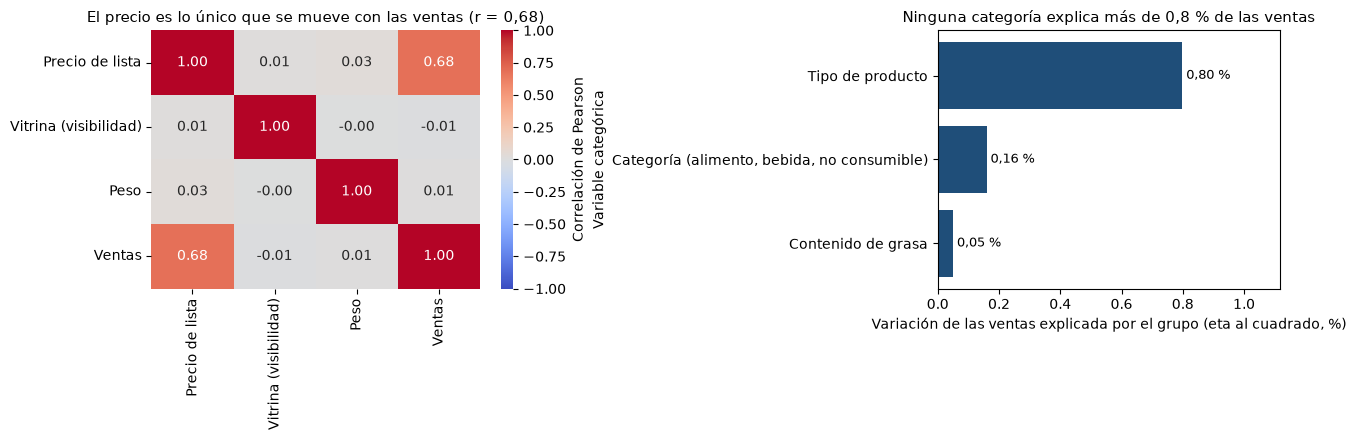

Cómo se calculó: Pearson sobre las 4461 filas de entrenamiento (parejas completas); eta² = 1 - suma de cuadrados dentro del grupo / suma de cuadrados total.
Todas las variables entran al modelo: el precio por su correlación; las categóricas y el peso para que el modelo mismo diga si aportan algo.


,Precio de lista,Vitrina (visibilidad),Peso,Ventas
Precio de lista,1.000,0.008,0.028,0.680
Vitrina (visibilidad),0.008,1.000,-0.002,-0.009
Peso,0.028,-0.002,1.000,0.007
Ventas,0.680,-0.009,0.007,1.000


In [12]:
entren = Xtr.assign(ventas=ytr)
corr_m = entren[NUM + ["ventas"]].corr()
etiquetas = {"Item_MRP": "Precio de lista", "Item_Visibility": "Vitrina (visibilidad)", "Item_Weight": "Peso", "ventas": "Ventas"}
corr_m = corr_m.rename(index=etiquetas, columns=etiquetas)


def eta2(grupo, valor):
    medias = valor.groupby(grupo).transform("mean")
    return 1 - ((valor - medias) ** 2).sum() / ((valor - valor.mean()) ** 2).sum()


eta = pd.Series({c: eta2(entren[c], entren["ventas"]) for c in CAT}, name="eta al cuadrado").sort_values(ascending=False)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.2, 1]})
sns.heatmap(corr_m, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ejes[0], cbar_kws={"label": "Correlación de Pearson"})
r_precio = corr_m.loc["Ventas", "Precio de lista"]
ejes[0].set_title(f"El precio es lo único que se mueve con las ventas (r = {fmt(r_precio, 2)})", fontsize=11)
nombres_cat = {"Item_Type": "Tipo de producto", "Item_Fat_Content": "Contenido de grasa", "Categoria_producto": "Categoría (alimento, bebida, no consumible)"}
ejes[1].barh([nombres_cat[i] for i in eta.index[::-1]], eta.values[::-1] * 100, color="#1f4e79")
ejes[1].set_xlabel("Variación de las ventas explicada por el grupo (eta al cuadrado, %)")
ejes[1].set_ylabel("Variable categórica")
ejes[1].set_title(f"Ninguna categoría explica más de {fmt(eta.max() * 100, 1)} % de las ventas", fontsize=11)
ejes[1].set_xlim(0, max(1.0, eta.max() * 100 * 1.4))
for i, v in enumerate(eta.values[::-1]):
    ejes[1].text(v * 100, i, f" {fmt(v * 100, 2)} %", va="center", fontsize=9)
plt.tight_layout()
plt.show()
print(f"Cómo se calculó: Pearson sobre las {len(entren)} filas de entrenamiento (parejas completas); eta² = 1 - suma de cuadrados dentro del grupo / suma de cuadrados total.")
print("Todas las variables entran al modelo: el precio por su correlación; las categóricas y el peso para que el modelo mismo diga si aportan algo.")
display(corr_m.round(3))

## 12. Línea base y tres algoritmos, con su razón de ser

| Modelo | Por qué está |
|---|---|
| `DummyRegressor(strategy="mean")` | **Piso.** Predice siempre la media de entrenamiento. Si el modelo no le gana, no hay modelo |
| Árbol de decisión | El algoritmo de la clase 13: se puede leer y mide la no linealidad |
| Ridge (regresión lineal con penalización) | Contraste interpretable: si un modelo lineal simple iguala a los demás, la relación es simple |
| Random Forest | Ensamble de árboles: captura interacciones; si no mejora al Ridge, la complejidad no paga |

**Ajuste razonable y documentado.** Una grilla pequeña por modelo, validación cruzada de 5 particiones
(`KFold`, `shuffle=True`, `random_state=42`) **solo sobre entrenamiento**, métrica de selección MAE. Las
columnas se imputan y codifican dentro del `Pipeline`, dentro de cada partición de la validación cruzada. Cada
configuración probada se guarda en `datos_procesados/registro_experimentos.csv`.

In [13]:
def preparar(escalar):
    numericas = [("imp", SimpleImputer(strategy="median"))] + ([("esc", StandardScaler())] if escalar else [])
    categoricas = [("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore"))]
    return ColumnTransformer([("n", Pipeline(numericas), NUM), ("c", Pipeline(categoricas), CAT)])


def pipeline(modelo, escalar=False):
    return Pipeline([("p", preparar(escalar)), ("m", modelo)])


cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
candidatos = {
    "Árbol de decisión": (pipeline(DecisionTreeRegressor(random_state=RANDOM_STATE)),
                          {"m__max_depth": [2, 3, 5, 8], "m__min_samples_leaf": [1, 20, 50]}),
    "Ridge": (pipeline(Ridge(), escalar=True), {"m__alpha": [0.1, 1, 10, 100]}),
    "Random Forest": (pipeline(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
                      {"m__max_depth": [5, 10, None], "m__min_samples_leaf": [5, 20]}),
}


def metricas(modelo, Xa, ya, Xb, yb):
    pa, pb = modelo.predict(Xa), modelo.predict(Xb)
    return {"R2 entrenamiento": r2_score(ya, pa), "R2 prueba": r2_score(yb, pb),
            "gap R2": r2_score(ya, pa) - r2_score(yb, pb),
            "MAE prueba": mean_absolute_error(yb, pb), "RMSE prueba": np.sqrt(mean_squared_error(yb, pb))}


modelos, resultados, registro = {}, {}, []

# Dummy (piso)
dummy = pipeline(DummyRegressor(strategy="mean")).fit(Xtr, ytr)
cv_dummy = -GridSearchCV(pipeline(DummyRegressor(strategy="mean")), {}, cv=cv, scoring="neg_mean_absolute_error").fit(Xtr, ytr).best_score_
resultados["Dummy (media)"] = {"cv_mae": cv_dummy, "parametros": "strategy=mean", **metricas(dummy, Xtr, ytr, Xte, yte)}
modelos["Dummy (media)"] = dummy

for nombre, (pipe, grilla) in candidatos.items():
    gs = GridSearchCV(pipe, grilla, cv=cv, scoring="neg_mean_absolute_error", refit=True).fit(Xtr, ytr)
    modelos[nombre] = gs.best_estimator_
    resultados[nombre] = {"cv_mae": -gs.best_score_,
                          "parametros": {k.replace("m__", ""): v for k, v in gs.best_params_.items()},
                          **metricas(gs.best_estimator_, Xtr, ytr, Xte, yte)}  # la prueba se usa una vez por modelo
    for p, s in zip(gs.cv_results_["params"], gs.cv_results_["mean_test_score"]):
        registro.append({"modelo": nombre, "configuración": str({k.replace("m__", ""): v for k, v in p.items()}),
                         "MAE validación cruzada (entrenamiento)": -s})

tabla = pd.DataFrame(resultados).T
cols_num = ["cv_mae", "R2 entrenamiento", "R2 prueba", "gap R2", "MAE prueba", "RMSE prueba"]
display(tabla[["parametros"] + cols_num].astype({c: float for c in cols_num}).round(3))
print(f"Tamaño del conjunto de prueba: {len(yte)} filas. Una métrica sobre {len(yte)} casos se mueve un poco con otra partición (ver sección 14).")

,parametros,cv_mae,R2 entrenamiento,R2 prueba,gap R2,MAE prueba,RMSE prueba
Dummy (media),strategy=mean,1196.483,0.000,-0.000,0.000,1229.224,1538.117
Árbol de decisión,"{'max_depth': 3, 'min_samples_leaf': 20}",821.991,0.464,0.468,-0.004,835.991,1121.458
Ridge,{'alpha': 100},816.010,0.464,0.476,-0.011,825.412,1113.433
Random Forest,"{'max_depth': 5, 'min_samples_leaf': 5}",816.192,0.496,0.471,0.024,827.335,1118.093


Tamaño del conjunto de prueba: 1116 filas. Una métrica sobre 1116 casos se mueve un poco con otra partición (ver sección 14).


## 13. Elección del modelo, con la regla fijada antes

Se aplica la regla de la sección 9 sin tocarla: filtro por gap, luego menor MAE de validación cruzada, con
desempate por simplicidad. La regla de gap de la clase 13 es: menor de 0,05 bien, de 0,05 a 0,10 aceptable,
mayor de 0,10 sobreajuste.

Ridge              MAE validación cruzada =   816,0 | gap R2 = -0,011 (bien) | elegible
Árbol de decisión  MAE validación cruzada =   822,0 | gap R2 = -0,004 (bien) | elegible
Random Forest      MAE validación cruzada =   816,2 | gap R2 = 0,024 (bien) | elegible

Modelos a menos de 1 % del mejor MAE de validación cruzada: ['Ridge', 'Árbol de decisión', 'Random Forest']
Modelo elegido: Ridge  con {'alpha': 100}

MAE de prueba: Dummy 1.229 contra Ridge 825  -> el modelo reduce el error 32,9 % frente al piso
R2 de prueba del modelo elegido: 0,476 (el Dummy tiene -0,000 por construcción)


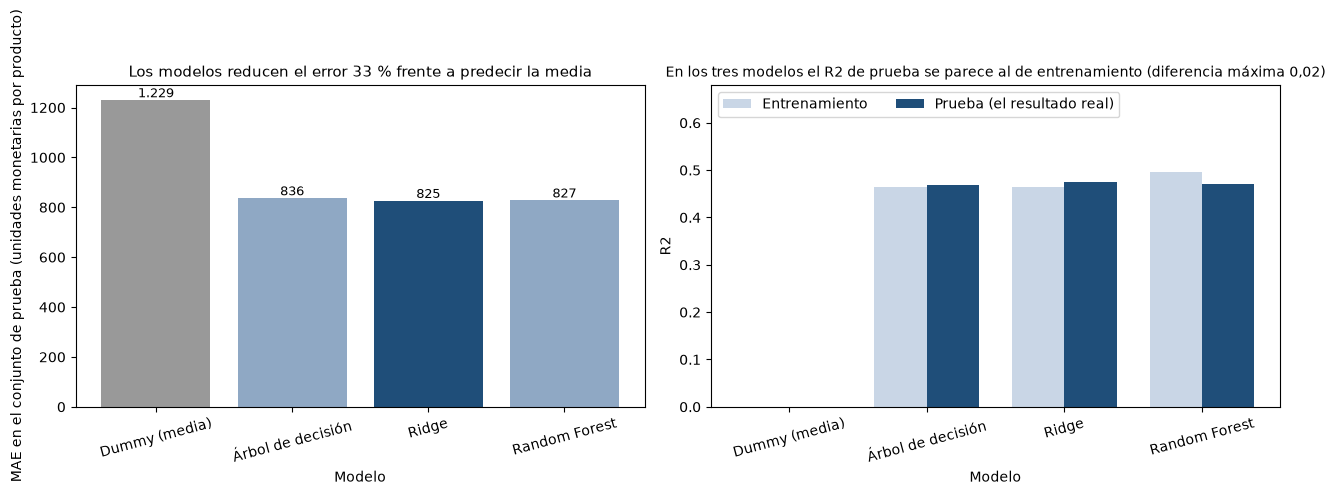

Cómo se calculó: MAE = promedio de |venta real - venta predicha|; R2 = 1 - SS_residual / SS_total; gap = R2 entrenamiento - R2 prueba. Entrenamiento n = 4461, prueba n = 1116, random_state = 42.


In [14]:
def diagnostico(gap):
    return "bien" if gap < 0.05 else ("aceptable" if gap <= 0.10 else "SOBREAJUSTE")


orden_simple = ["Ridge", "Árbol de decisión", "Random Forest"]
elegibles = [m for m in orden_simple if resultados[m]["gap R2"] < 0.10]
mejor_cv = min(resultados[m]["cv_mae"] for m in elegibles)
empatados = [m for m in elegibles if resultados[m]["cv_mae"] <= mejor_cv * 1.01]
elegido = min(empatados, key=orden_simple.index)

for m in orden_simple:
    r = resultados[m]
    print(f"{m:18s} MAE validación cruzada = {fmt(r['cv_mae'], 1):>7s} | gap R2 = {fmt(r['gap R2'], 3)} ({diagnostico(r['gap R2'])}) "
          f"| {'elegible' if m in elegibles else 'descartado por gap'}")
print(f"\nModelos a menos de 1 % del mejor MAE de validación cruzada: {empatados}")
print(f"Modelo elegido: {elegido}  con {resultados[elegido]['parametros']}")

dummy_mae = resultados["Dummy (media)"]["MAE prueba"]
mejora_mae = 1 - resultados[elegido]["MAE prueba"] / dummy_mae
print(f"\nMAE de prueba: Dummy {fmt(dummy_mae)} contra {elegido} {fmt(resultados[elegido]['MAE prueba'])}  -> el modelo reduce el error {fmt(mejora_mae * 100, 1)} % frente al piso")
print(f"R2 de prueba del modelo elegido: {fmt(resultados[elegido]['R2 prueba'], 3)} (el Dummy tiene {fmt(resultados['Dummy (media)']['R2 prueba'], 3)} por construcción)")

for nombre, r in resultados.items():
    registro.append({"modelo": nombre, "configuración": "MEJOR de su grilla" if nombre != "Dummy (media)" else "strategy=mean",
                     "MAE validación cruzada (entrenamiento)": r["cv_mae"], "R2 prueba": r["R2 prueba"], "MAE prueba": r["MAE prueba"],
                     "gap R2": r["gap R2"], "elegido": nombre == elegido})
pd.DataFrame(registro).to_csv("datos_procesados/registro_experimentos.csv", index=False)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
nombres = list(resultados)
colores = ["#999999" if n.startswith("Dummy") else ("#1f4e79" if n == elegido else "#8fa8c4") for n in nombres]
ejes[0].bar(nombres, [resultados[n]["MAE prueba"] for n in nombres], color=colores)
for i, n in enumerate(nombres):
    ejes[0].text(i, resultados[n]["MAE prueba"], fmt(resultados[n]["MAE prueba"]), ha="center", va="bottom", fontsize=9)
ejes[0].set_ylabel("MAE en el conjunto de prueba (unidades monetarias por producto)")
ejes[0].set_xlabel("Modelo")
ejes[0].set_title(f"Los modelos reducen el error {fmt(mejora_mae * 100, 0)} % frente a predecir la media", fontsize=11)
ejes[0].tick_params(axis="x", labelrotation=15)
ancho = 0.38
posi = np.arange(len(nombres))
ejes[1].bar(posi - ancho / 2, [resultados[n]["R2 entrenamiento"] for n in nombres], ancho, label="Entrenamiento", color="#c9d6e6")
ejes[1].bar(posi + ancho / 2, [resultados[n]["R2 prueba"] for n in nombres], ancho, label="Prueba (el resultado real)", color="#1f4e79")
ejes[1].set_xticks(posi, nombres)
ejes[1].tick_params(axis="x", labelrotation=15)
ejes[1].set_ylabel("R2")
ejes[1].set_xlabel("Modelo")
gap_max = max(abs(resultados[n]["gap R2"]) for n in nombres if not n.startswith("Dummy"))
ejes[1].set_ylim(0, 0.68)
ejes[1].legend(loc="upper left", ncol=2)
ejes[1].set_title(f"En los tres modelos el R2 de prueba se parece al de entrenamiento (diferencia máxima {fmt(gap_max, 2)})", fontsize=10)
plt.tight_layout()
plt.show()
print("Cómo se calculó: MAE = promedio de |venta real - venta predicha|; R2 = 1 - SS_residual / SS_total; gap = R2 entrenamiento - R2 prueba. "
      f"Entrenamiento n = {len(ytr)}, prueba n = {len(yte)}, random_state = 42.")

## 14. Robustez: ¿cambia algo si el modelo nunca vio el producto?

La partición aleatoria deja el mismo producto (en otra tienda) a ambos lados del corte. Eso es coherente con el
uso real, porque las tiendas de barrio venden los mismos productos que los supermercados, pero puede inflar
la métrica. Se repite con una partición **por producto** (`GroupShuffleSplit`): ningún producto de prueba aparece en entrenamiento.
Se reutilizan los hiperparámetros ya elegidos, sin volver a ajustar.

In [15]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
i_tr, i_te = next(gss.split(X, y, groups=fuente["Item_Identifier"]))
Xg_tr, Xg_te, yg_tr, yg_te = X.iloc[i_tr], X.iloc[i_te], y.iloc[i_tr], y.iloc[i_te]
assert not set(fuente["Item_Identifier"].iloc[i_tr]) & set(fuente["Item_Identifier"].iloc[i_te])

filas = {}
for nombre in ["Dummy (media)", elegido]:
    m = clone(modelos[nombre]).fit(Xg_tr, yg_tr)
    filas[nombre] = metricas(m, Xg_tr, yg_tr, Xg_te, yg_te)
rob = pd.DataFrame(filas).T
display(rob.round(3))
print(f"Partición por producto: entrenamiento {len(yg_tr)} filas, prueba {len(yg_te)} filas (productos distintos).")
mejora_g = 1 - rob.loc[elegido, "MAE prueba"] / rob.loc["Dummy (media)", "MAE prueba"]
print(f"Con productos nunca vistos, el {elegido} reduce el MAE {fmt(mejora_g * 100, 1)} % frente al Dummy (en la partición aleatoria fue {fmt(mejora_mae * 100, 1)} %), y el gap de R2 es {fmt(rob.loc[elegido, 'gap R2'], 3)}.")

,R2 entrenamiento,R2 prueba,gap R2,MAE prueba,RMSE prueba
Dummy (media),0.000,-0.002,0.002,1220.263,1521.138
Ridge,0.463,0.481,-0.019,790.707,1094.400


Partición por producto: entrenamiento 4438 filas, prueba 1139 filas (productos distintos).
Con productos nunca vistos, el Ridge reduce el MAE 35,2 % frente al Dummy (en la partición aleatoria fue 32,9 %), y el gap de R2 es -0,019.


## 15. Variables clave: asociación, no causa

Se mide cuánto empeora el MAE de prueba al **desordenar una variable** (importancia por permutación, 20
repeticiones, `random_state=42`): si desordenarla no cambia nada, el modelo no la usa. Se calcula sobre las
variables originales, tal como entran al `Pipeline`. Si el modelo elegido trae `feature_importances_`, se
muestra también, sumando las columnas que salen de una misma variable.

**Qué no se puede concluir.** Que una variable sea importante dice que el modelo la usa para
predecir, no que cambiarla cambie las ventas. El precio importa porque los productos caros venden más, no porque
bajar el precio de un producto lo haga vender más.

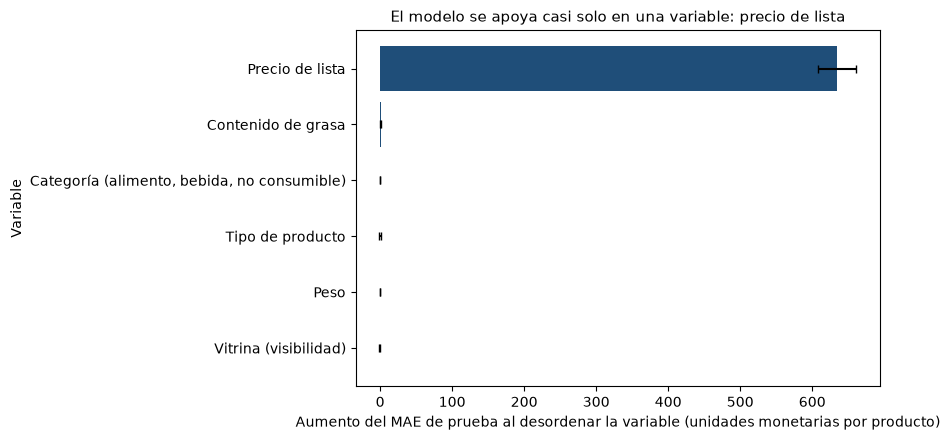

,Aumento del MAE al desordenar,Desviación (20 repeticiones)
Item_MRP,634.79,26.17
Item_Fat_Content,0.79,0.56
Categoria_producto,0.26,0.24
Item_Type,-0.16,0.79
Item_Weight,-0.17,0.38
Item_Visibility,-0.38,0.58


Cómo se calculó: importancia por permutación sobre las 1116 filas de prueba; scoring = menos MAE; 20 repeticiones.
Lectura: es asociación, no causalidad. Ninguna de estas importancias dice que mover la variable mueva las ventas.


In [16]:
final = modelos[elegido]
perm = permutation_importance(final, Xte, yte, scoring="neg_mean_absolute_error", n_repeats=20, random_state=RANDOM_STATE)
imp_perm = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)
imp_std = pd.Series(perm.importances_std, index=FEATURES)[imp_perm.index]


def importancias_integradas(pipe):
    m = pipe.named_steps["m"]
    if not hasattr(m, "feature_importances_"):
        return None
    nombres = pipe.named_steps["p"].get_feature_names_out()
    acumulado = {}
    for n, v in zip(nombres, m.feature_importances_):
        base = n.split("__", 1)[1]
        var = next((c for c in sorted(CAT, key=len, reverse=True) if base.startswith(c + "_")), base)
        acumulado[var] = acumulado.get(var, 0) + v
    return pd.Series(acumulado).sort_values(ascending=False)


imp_int = importancias_integradas(final)
nombres_legibles = {"Item_MRP": "Precio de lista", "Item_Visibility": "Vitrina (visibilidad)", "Item_Weight": "Peso",
                    "Item_Type": "Tipo de producto", "Item_Fat_Content": "Contenido de grasa", "Categoria_producto": "Categoría (alimento, bebida, no consumible)"}

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh([nombres_legibles[i] for i in imp_perm.index[::-1]], imp_perm.values[::-1], xerr=imp_std.values[::-1], color="#1f4e79", capsize=3)
ax.set_xlabel("Aumento del MAE de prueba al desordenar la variable (unidades monetarias por producto)")
ax.set_ylabel("Variable")
ax.set_title(f"El modelo se apoya casi solo en una variable: {nombres_legibles[imp_perm.index[0]].lower()}", fontsize=11)
plt.tight_layout()
plt.show()
display(pd.DataFrame({"Aumento del MAE al desordenar": imp_perm, "Desviación (20 repeticiones)": imp_std}).round(2))
if imp_int is not None:
    print("feature_importances_ del modelo elegido, sumadas por variable original:")
    display(imp_int.round(3).to_frame("importancia"))
print(f"Cómo se calculó: importancia por permutación sobre las {len(yte)} filas de prueba; scoring = menos MAE; 20 repeticiones.")
print("Lectura: es asociación, no causalidad. Ninguna de estas importancias dice que mover la variable mueva las ventas.")

## 16. Qué venderían las tiendas de barrio como Supermercado Tipo 1

Se aplica el modelo elegido (entrenado solo con Tipo 1 y solo con entrenamiento) a las 1.083 filas de las tiendas de
barrio. **Es un escenario, no una predicción**: supone que un producto de barrio, convertido a formato Tipo 1, vendería
lo que un producto con sus mismas características vende en un Tipo 1.

**El rango.** Se remuestrean 1.000 veces (`random_state=42`) los residuos del conjunto de prueba, 1.083 por vez, se suman a
la predicción total y se toman los percentiles 5 y 95. Este rango cubre **solo el ruido de la predicción fila a fila**. No cubre lo más
importante: que un formato distinto puede comportarse distinto (extrapolación). Por eso se muestran también las
predicciones de los otros modelos, y se comprueba qué tanto se parecen los productos de barrio a los de Tipo 1.

In [17]:
# ¿Se parecen los productos de barrio a los de entrenamiento? (si no, el modelo extrapolaría)
comp = pd.DataFrame({
    "entrenamiento Tipo 1": [Xtr["Item_MRP"].mean(), Xtr["Item_MRP"].median(), (Xtr["Categoria_producto"] == "Alimentos").mean() * 100, Xtr["Item_Weight"].mean()],
    "tienda de barrio": [objetivo["Item_MRP"].mean(), objetivo["Item_MRP"].median(), (objetivo["Categoria_producto"] == "Alimentos").mean() * 100, objetivo["Item_Weight"].mean()],
}, index=["Precio de lista, media", "Precio de lista, mediana", "% alimentos", "Peso, media"])
display(comp.round(1))
dentro = objetivo["Item_MRP"].between(Xtr["Item_MRP"].min(), Xtr["Item_MRP"].max()).mean()
print(f"Filas de barrio con precio dentro del rango de entrenamiento: {fmt(dentro * 100, 1)} %")

pred = final.predict(objetivo[FEATURES])
ventas_actuales = objetivo[V].sum()
residuos = (yte - final.predict(Xte)).values
rng = np.random.default_rng(RANDOM_STATE)
totales = pred.sum() + rng.choice(residuos, size=(1000, len(objetivo))).sum(axis=1)
p5, p95 = np.percentile(totales, [5, 95])
neto, neto5, neto95 = pred.sum() - ventas_actuales, p5 - ventas_actuales, p95 - ventas_actuales

print(f"\nVentas anuales esperadas de las {len(objetivo)} filas de barrio como Tipo 1 ({elegido}): {fmt(pred.sum())}")
print(f"Ventas actuales de esas filas: {fmt(ventas_actuales)}")
print(f"Incremento anual esperado (escenario): {fmt(neto)}   rango 5 %-95 % del ruido de predicción: [{fmt(neto5)}, {fmt(neto95)}]")
print(f"Como % de las ventas de la cadena: {fmt(neto / total * 100, 1)} %")

otros = {}
for nombre in orden_simple:
    otros[nombre] = modelos[nombre].predict(objetivo[FEATURES]).sum() - ventas_actuales
tabla_inc = pd.DataFrame({"incremento anual esperado": otros}).round(0)
display(tabla_inc)
rango_modelos = (min(otros.values()), max(otros.values()))
print(f"Rango entre los tres modelos: [{fmt(rango_modelos[0])}, {fmt(rango_modelos[1])}]")

techo_m2 = dif * len(objetivo)
dentro_rango = neto5 <= techo_m2 <= neto95
print(f"\nTecho del M2 (diferencia de medias x filas): {fmt(techo_m2)}. ¿Dentro del rango del ruido de predicción? {'sí' if dentro_rango else 'NO'}.")
print(f"Diferencia entre el modelo ({elegido}) y el techo del M2: {fmt(neto - techo_m2)} ({fmt((neto - techo_m2) / techo_m2 * 100, 1)} %)")

,entrenamiento Tipo 1,tienda de barrio
"Precio de lista, media",141.1,140.3
"Precio de lista, mediana",142.9,143.9
% alimentos,71.8,71.2
"Peso, media",12.8,12.9


Filas de barrio con precio dentro del rango de entrenamiento: 100,0 %



Ventas anuales esperadas de las 1083 filas de barrio como Tipo 1 (Ridge): 2.470.182
Ventas actuales de esas filas: 368.034
Incremento anual esperado (escenario): 2.102.148   rango 5 %-95 % del ruido de predicción: [2.010.395, 2.126.665]
Como % de las ventas de la cadena: 11,3 %


,incremento anual esperado
Ridge,2102148.0
Árbol de decisión,2127093.0
Random Forest,2125152.0


Rango entre los tres modelos: [2.102.148, 2.127.093]

Techo del M2 (diferencia de medias x filas): 2.140.390. ¿Dentro del rango del ruido de predicción? NO.
Diferencia entre el modelo (Ridge) y el techo del M2: -38.242 (-1,8 %)


OUT019: ventas actuales 179.694; ventas esperadas como Tipo 1 (modelo) 1.198.903 -> 6,7 veces las actuales
  Meta x1,5: incremento de 89.847 al año = 9 % del incremento que estima el modelo
  Meta x2,0: incremento de 179.694 al año = 18 % del incremento que estima el modelo
  Meta x3,0: incremento de 359.388 al año = 35 % del incremento que estima el modelo


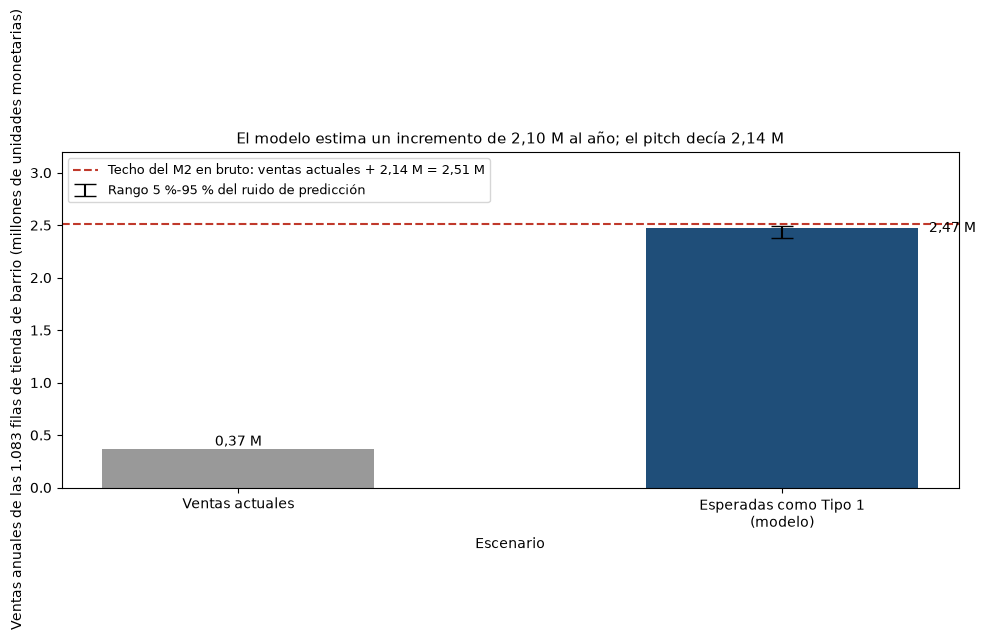

Cómo se calculó: suma de la predicción del modelo sobre las 1.083 filas de barrio; rango = percentiles 5 y 95 de 1.000 remuestreos de residuos de prueba (random_state = 42). El rango cubre solo el ruido fila a fila, no la extrapolación entre formatos. Escenario, no predicción.


In [18]:
# Lectura para el piloto: ¿cuánto del techo exigen las metas?
o19 = objetivo[objetivo["Outlet_Identifier"] == "OUT019"]
pred19 = final.predict(o19[FEATURES]).sum()
actual19 = o19[V].sum()
multiplo_techo = pred19 / actual19
print(f"OUT019: ventas actuales {fmt(actual19)}; ventas esperadas como Tipo 1 (modelo) {fmt(pred19)} -> {fmt(multiplo_techo, 1)} veces las actuales")
for meta in (1.5, 2, 3):
    print(f"  Meta x{fmt(meta, 1)}: incremento de {fmt(actual19 * (meta - 1))} al año = {fmt((meta - 1) / (multiplo_techo - 1) * 100, 0)} % del incremento que estima el modelo")

fig, ax = plt.subplots(figsize=(10, 4.5))
nombres_b = ["Ventas actuales", "Esperadas como Tipo 1\n(modelo)"]
ax.bar(nombres_b, [ventas_actuales / 1e6, pred.sum() / 1e6], color=["#999999", "#1f4e79"], width=0.5)
ax.errorbar([1], [pred.sum() / 1e6], yerr=[[(pred.sum() - p5) / 1e6], [(p95 - pred.sum()) / 1e6]], fmt="none", ecolor="black", capsize=8, label="Rango 5 %-95 % del ruido de predicción")
techo_bruto = ventas_actuales + techo_m2
ax.axhline(techo_bruto / 1e6, color="#c0392b", linestyle="--", label=f"Techo del M2 en bruto: ventas actuales + {fmt(techo_m2 / 1e6, 2)} M = {fmt(techo_bruto / 1e6, 2)} M")
ax.text(0, ventas_actuales / 1e6, f"{fmt(ventas_actuales / 1e6, 2)} M", ha="center", va="bottom", fontsize=10)
ax.text(1.27, pred.sum() / 1e6, f"{fmt(pred.sum() / 1e6, 2)} M", ha="left", va="center", fontsize=10)
ax.set_ylim(0, 3.2)
ax.set_ylabel("Ventas anuales de las 1.083 filas de tienda de barrio (millones de unidades monetarias)")
ax.set_xlabel("Escenario")
ax.set_title(f"El modelo estima un incremento de {fmt(neto / 1e6, 2)} M al año; el pitch decía {fmt(techo_m2 / 1e6, 2)} M", fontsize=11)
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()
print("Cómo se calculó: suma de la predicción del modelo sobre las 1.083 filas de barrio; rango = percentiles 5 y 95 de 1.000 remuestreos de residuos de prueba (random_state = 42). "
      "El rango cubre solo el ruido fila a fila, no la extrapolación entre formatos. Escenario, no predicción.")

## 17. Validación contra el criterio de aceptación

Cada condición de la sección 9, contra lo que salió. Se imprime desde el código.

In [19]:
cond = []
cond.append(("1. Partición 80/20, random_state=42, antes de imputar; transformaciones dentro del Pipeline",
             len(Xtr) + len(Xte) == len(fuente) and all(isinstance(m, Pipeline) for m in modelos.values())))
cond.append(("2. Sin fuga (sin Outlet_*, Item_Identifier ni la respuesta en X)", not prohibidas & set(FEATURES)))
cond.append((f"3. MAE de prueba al menos 20 % menor que el Dummy (sale {fmt(mejora_mae * 100, 1)} %)", mejora_mae >= 0.20))
cond.append((f"4. Gap de R2 del elegido menor que 0,10 (sale {fmt(resultados[elegido]['gap R2'], 3)}, {diagnostico(resultados[elegido]['gap R2'])})", resultados[elegido]["gap R2"] < 0.10))
cond.append(("5. Elección con validación cruzada de 5 particiones solo sobre entrenamiento", cv.get_n_splits() == 5))
cond.append(("6. Estimación como rango (percentiles 5 y 95 de 1.000 remuestreos) y como escenario", p5 < pred.sum() < p95 and len(totales) == 1000))
cond.append((f"7. Techo del M2 ({fmt(techo_m2)}) contra el rango del modelo [{fmt(neto5)}, {fmt(neto95)}]: {'DENTRO, techo corroborado' if dentro_rango else 'FUERA: la cifra del pitch se revisa y se dice (ver abajo)'}", dentro_rango))
cond.append(("8. Limitaciones dichas (secciones 15, 16 y 18): se verifica leyéndolas, no con código", None))
for texto, ok in cond:
    estado = "REVISAR " if ok is None else ("CUMPLE  " if ok else "NO CUMPLE")
    print(f"[{estado}] {texto}")
if not dentro_rango:
    print(f"\nLa regla de la condición 7 se aplica tal como se escribió: el techo del M2 queda fuera del rango, {fmt(abs(techo_m2 - neto95))} por encima del extremo superior. "
          f"La diferencia entre las dos estimaciones es de {fmt(abs(neto - techo_m2) / techo_m2 * 100, 1)} %, dentro del redondeo de '2,1 millones' que usa el pitch. "
          "La cifra del pitch se presenta como 'alrededor de 2,1 millones' con las dos estimaciones a la vista, sin retocar ninguna para que encajen.")

print("\nLas cuatro preguntas del analista:")
print(f"- ¿La métrica tiene sentido? R2 de prueba = {fmt(resultados[elegido]['R2 prueba'], 2)}: moderado, no alto. El precio explica casi todo y el resto es ruido que estos datos no capturan. Un R2 así no se celebra: se dice.")
print(f"- ¿La forma cuadra? Entrenamiento {len(Xtr)}, prueba {len(Xte)} (partición por producto: {len(yg_te)}), {len(objetivo)} filas de barrio. La métrica de prueba se mueve con la partición.")
print(f"- ¿Responde lo que pregunté? Responde cuánto venderían esos productos como Tipo 1; no responde si convertir la tienda lo logra.")
print(f"- ¿Cambió algo? El modelo reduce el error {fmt(mejora_mae * 100, 0)} % frente al piso, y su estimación del incremento ({fmt(neto / 1e6, 2)} M) {'coincide con' if abs(neto - techo_m2) / techo_m2 < 0.1 else 'difiere de'} el techo del M2 ({fmt(techo_m2 / 1e6, 2)} M). Ojo: la coincidencia es esperable, porque los productos de barrio tienen casi el mismo precio medio ({fmt(objetivo['Item_MRP'].mean())} contra {fmt(Xtr['Item_MRP'].mean())}) y las mismas categorías que los de Tipo 1. No es una confirmación independiente: es la misma brecha vista controlando por precio y tipo de producto.")

[CUMPLE  ] 1. Partición 80/20, random_state=42, antes de imputar; transformaciones dentro del Pipeline
[CUMPLE  ] 2. Sin fuga (sin Outlet_*, Item_Identifier ni la respuesta en X)
[CUMPLE  ] 3. MAE de prueba al menos 20 % menor que el Dummy (sale 32,9 %)
[CUMPLE  ] 4. Gap de R2 del elegido menor que 0,10 (sale -0,011, bien)
[CUMPLE  ] 5. Elección con validación cruzada de 5 particiones solo sobre entrenamiento
[CUMPLE  ] 6. Estimación como rango (percentiles 5 y 95 de 1.000 remuestreos) y como escenario
[NO CUMPLE] 7. Techo del M2 (2.140.390) contra el rango del modelo [2.010.395, 2.126.665]: FUERA: la cifra del pitch se revisa y se dice (ver abajo)
[REVISAR ] 8. Limitaciones dichas (secciones 15, 16 y 18): se verifica leyéndolas, no con código

La regla de la condición 7 se aplica tal como se escribió: el techo del M2 queda fuera del rango, 13.725 por encima del extremo superior. La diferencia entre las dos estimaciones es de 1,8 %, dentro del redondeo de '2,1 millones' que usa el pitc

## 18. Qué significa para quien decide, y qué no respaldan los datos

La conclusión cuantitativa y las salvedades están impresas arriba con sus cifras. Para el decisor:

- **Qué significa.** La diferencia de medias del M2 y un modelo que controla por precio y tipo de producto estiman un
  incremento anual del mismo orden de magnitud. Eso descarta que la brecha venga de vender productos más baratos o
  de otra categoría: los productos de barrio son, en promedio, tan caros como los de Tipo 1 y aun así venden 6,8 veces
  menos. **No es una confirmación independiente** (las dos estimaciones parten de la misma comparación entre
  formatos); es la misma brecha vista con control por producto.
- **Qué hace el modelo en la decisión.** No cambia la recomendación del M2: la refuerza y ubica las metas del
  piloto como una fracción del techo. Las metas ×1,5, ×2 y ×3 piden menos de la mitad de lo que el modelo estima.
- **Qué no respaldan los datos.**
  1. Que convertir la tienda cause el aumento: el modelo aprende de supermercados y se aplica a otro formato, sin
     observar una sola tienda de barrio convertida. Solo el piloto lo prueba.
  2. Una cifra anual exacta: es un escenario con rango, y el rango real es más ancho que el que calcula el ruido de prediccion.
  3. Que el techo se repita cada año o llegue en tres meses.
  4. Una rentabilidad: el costo del piloto no está en los datos y queda como **supuesto abierto**.
  5. Un efecto de la vitrina, ni a favor ni en contra: no hay evidencia en estos datos.

## 19. Exportar las cifras para la presentación

La presentación del Momento 3 lee estas cifras de `datos_procesados/resultados_m3.json`: así ninguna cifra de las
láminas se escribe a mano.

In [20]:
import json

vit_tipo1 = df.loc[df["formato"] == "Supermercado Tipo 1", "vitrina"]
nivel1 = pares.loc["Emparejado, nivel 1: OUT019 contra OUT046 y OUT049 (solo Tipo 1)"]
nivel3 = pares.loc["Emparejado, nivel 3: OUT010 contra OUT013 (solo Tipo 1)"]
mezclado3 = pares.loc["Pitch M2, nivel 3: OUT010 contra Tipo 1 + Tipo 2 + Tipo 3 (mezcla)"]
vecinas = df.loc[df["Outlet_Identifier"].isin(["OUT046", "OUT049"]), V].mean()

salida = {
    "ic": {n: {"n": int(f["n"]), "media": float(f["media"]), "inf": float(f["IC95 inferior"]), "sup": float(f["IC95 superior"])} for n, f in ic.iterrows()},
    "welch": {"dif": float(dif), "inf": float(ci_dif.low), "sup": float(ci_dif.high), "t": float(welch.statistic), "gl": float(gl),
              "p": float(welch.pvalue), "d": float(d_cohen), "razon": float(razon)},
    "pareada": {"n": int(len(dif_prod)), "dif": float(dif_prod.mean()), "inf": float(ic_par[0]), "sup": float(ic_par[1]),
                "mediana_razon": float(razon_mediana)},
    "pares": {"nivel1_razon": float(nivel1["mediana de la razón"]), "nivel1_n": int(nivel1["productos comunes"]),
              "nivel3_razon": float(nivel3["mediana de la razón"]), "nivel3_n": int(nivel3["productos comunes"]),
              "nivel3_mezclado_razon": float(mezclado3["mediana de la razón"]),
              "iguales_dif": float(iguales["diferencia media"]), "iguales_inf": float(iguales["IC95 inferior"]),
              "iguales_sup": float(iguales["IC95 superior"]), "iguales_n": int(iguales["productos comunes"])},
    "vitrina": {"barrio": float(vit_barrio.mean()), "tipo1": float(vit_tipo1.mean()),
                "ventas_barrio": float(barrio.mean()), "ventas_tipo1": float(tipo1.mean()),
                "corr_barrio": float(corr.loc["Tienda de barrio", "r"]), "corr_tipo1": float(corr.loc["Supermercado Tipo 1", "r"]),
                "coef": float(b1), "coef_inf": float(b1 - 1.96 * se_b1), "coef_sup": float(b1 + 1.96 * se_b1),
                "efectos": {str(p): {k2: float(v2) for k2, v2 in e.items()} for p, e in efectos.items()}},
    "brecha": {"techo": float(techo_m2), "por_producto": float(dif), "filas": int(len(objetivo)), "pct_cadena": float(techo_m2 / total * 100),
               "total_cadena": float(total)},
    "modelo": {"elegido": elegido, "n_train": int(len(Xtr)), "n_test": int(len(Xte)),
               "mae_prueba": float(resultados[elegido]["MAE prueba"]), "mae_dummy": float(dummy_mae),
               "mejora_mae": float(mejora_mae), "r2_prueba": float(resultados[elegido]["R2 prueba"]),
               "gap_r2": float(resultados[elegido]["gap R2"]), "mejora_mae_por_producto": float(mejora_g),
               "ventas_esperadas": float(pred.sum()), "ventas_actuales": float(ventas_actuales),
               "incremento": float(neto), "inc_p5": float(neto5), "inc_p95": float(neto95),
               "totales_p5": float(p5), "totales_p95": float(p95),
               "incremento_por_modelo": {k2: float(v2) for k2, v2 in otros.items()},
               "importancia_precio": float(imp_perm.iloc[0]), "variable_principal": str(imp_perm.index[0]),
               "dif_vs_techo_pct": float((neto - techo_m2) / techo_m2 * 100), "techo_dentro_rango": bool(dentro_rango)},
    "piloto": {"ventas": float(actual19), "esperadas_modelo": float(pred19), "multiplo_modelo": float(multiplo_techo),
               "productos": int((df["Outlet_Identifier"] == "OUT019").sum()), "por_producto": float(actual19 / (df["Outlet_Identifier"] == "OUT019").sum()),
               "vecinas_por_producto": float(vecinas)},
}
with open("datos_procesados/resultados_m3.json", "w", encoding="utf-8") as f:
    json.dump(salida, f, ensure_ascii=False, indent=1)
print("Escrito datos_procesados/resultados_m3.json con", len(salida), "bloques de cifras")

Escrito datos_procesados/resultados_m3.json con 8 bloques de cifras
